In [1]:

import numpy as np
import pandas as pd 

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


/kaggle/input/datasets/bahaabashtawi/dataset-4h/XAU_4h_data.csv


In [12]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def load_and_preprocess_data():
    df = pd.read_csv('XAU_4h_data.csv', sep=';')
    df = df.dropna().head(2000) 
    X = df[['Open']].values
    y = df['Close'].values
    
    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)
    
    scaler_X = StandardScaler()
    X_scaled = scaler_X.fit_transform(X_poly)
    
    scaler_y = StandardScaler()
    y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()
    
    return X_scaled, y_scaled

SGD Final Cost: 0.005162002539579016
SGD Final Theta: [1.00358167 2.96940919 3.97485929]


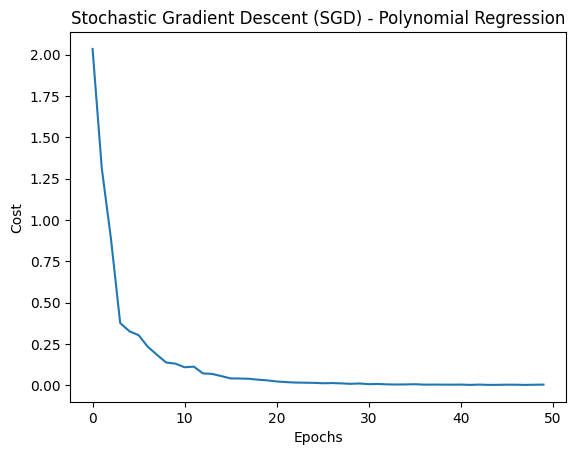

In [13]:
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(42)
m_samples = 100 
X_raw = 2 * np.random.rand(m_samples, 1) - 1
y_raw = 4 * (X_raw ** 2) + 3 * X_raw + 1 + 0.1 * np.random.randn(m_samples, 1)
y = y_raw.squeeze()


X = np.c_[np.ones(m_samples), X_raw, X_raw**2]
m, n = X.shape


theta = np.zeros(n)
learning_rate = 0.01
epochs = 50
costs = []


for epoch in range(epochs):
    cost_epoch = 0
    for i in range(m):
        random_index = np.random.randint(0, m)
        xi = X[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        
        prediction = np.dot(xi, theta)
        error = prediction - yi
        cost_epoch += error[0]**2
        
        gradient = xi.T * error
        theta -= learning_rate * gradient.flatten()
        
    costs.append(cost_epoch / (2 * m))


print("SGD Final Cost:", costs[-1])
print("SGD Final Theta:", theta)


plt.plot(costs)
plt.title("Stochastic Gradient Descent (SGD) - Polynomial Regression")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.savefig("sgd_cost.png")
plt.show()